In [1]:
from torch import nn
import torch
from torch.nn import functional as F

class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super(UNet, self).__init__()

        # Encoder (Contracting Path)
        # Block 1
        self.enc1_conv1 = nn.Conv2d(in_channels, 64, kernel_size=3, padding=1)
        self.enc1_conv2 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Block 2
        self.enc2_conv1 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.enc2_conv2 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Block 3
        self.enc3_conv1 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.enc3_conv2 = nn.Conv2d(256, 256, kernel_size=3, padding=1)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Block 4
        self.enc4_conv1 = nn.Conv2d(256, 512, kernel_size=3, padding=1)
        self.enc4_conv2 = nn.Conv2d(512, 512, kernel_size=3, padding=1)
        self.pool4 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Bottleneck
        self.bottleneck_conv1 = nn.Conv2d(512, 1024, kernel_size=3, padding=1)
        self.bottleneck_conv2 = nn.Conv2d(1024, 1024, kernel_size=3, padding=1)
        self.upconv4 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)

        # Decoder (Expanding Path)
        # Block 4
        self.dec4_conv1 = nn.Conv2d(1536, 512, kernel_size=3, padding=1) # 512 (from upconv) + 512 (from skip connection)
        self.dec4_conv2 = nn.Conv2d(512, 512, kernel_size=3, padding=1)
        self.upconv3 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)

        # Block 3
        self.dec3_conv1 = nn.Conv2d(768, 256, kernel_size=3, padding=1) # 256 (from upconv) + 256 (from skip connection)
        self.dec3_conv2 = nn.Conv2d(256, 256, kernel_size=3, padding=1)
        self.upconv2 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)

        # Block 2
        self.dec2_conv1 = nn.Conv2d(384, 128, kernel_size=3, padding=1) # 128 (from upconv) + 128 (from skip connection)
        self.dec2_conv2 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.upconv1 = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)

        # Block 1
        self.dec1_conv1 = nn.Conv2d(192, 64, kernel_size=3, padding=1) # 64 (from upconv) + 64 (from skip connection)
        self.dec1_conv2 = nn.Conv2d(64, 64, kernel_size=3, padding=1)

        # Output Layer
        self.output_conv = nn.Conv2d(64, out_channels, kernel_size=1)


    def forward(self, x):
        # Encoder
        enc1 = F.relu(self.enc1_conv1(x))
        enc1 = F.relu(self.enc1_conv2(enc1))
        enc1_pool = self.pool1(enc1)

        enc2 = F.relu(self.enc2_conv1(enc1_pool))
        enc2 = F.relu(self.enc2_conv2(enc2))
        enc2_pool = self.pool2(enc2)

        enc3 = F.relu(self.enc3_conv1(enc2_pool))
        enc3 = F.relu(self.enc3_conv2(enc3))
        enc3_pool = self.pool3(enc3)

        enc4 = F.relu(self.enc4_conv1(enc3_pool))
        enc4 = F.relu(self.enc4_conv2(enc4))
        enc4_pool = self.pool4(enc4)

        # Bottleneck
        bottleneck = F.relu(self.bottleneck_conv1(enc4_pool))
        bottleneck = F.relu(self.bottleneck_conv2(bottleneck))

        # Decoder
        dec4 = self.upconv4(bottleneck)
        # Concatenate with skip connection from encoder
        dec4 = torch.cat((dec4, enc4), dim=1)
        dec4 = F.relu(self.dec4_conv1(dec4))
        dec4 = F.relu(self.dec4_conv2(dec4))

        dec3 = self.upconv3(dec4)
        # Concatenate with skip connection from encoder
        dec3 = torch.cat((dec3, enc3), dim=1)
        dec3 = F.relu(self.dec3_conv1(dec3))
        dec3 = F.relu(self.dec3_conv2(dec3))

        dec2 = self.upconv2(dec3)
        # Concatenate with skip connection from encoder
        dec2 = torch.cat((dec2, enc2), dim=1)
        dec2 = F.relu(self.dec2_conv1(dec2))
        dec2 = F.relu(self.dec2_conv2(dec2))

        dec1 = self.upconv1(dec2)
        # Concatenate with skip connection from encoder
        dec1 = torch.cat((dec1, enc1), dim=1)
        dec1 = F.relu(self.dec1_conv1(dec1))
        dec1 = F.relu(self.dec1_conv2(dec1))

        # Output
        output = self.output_conv(dec1)

        return output

# Приклад використання:
# Створюємо екземпляр U-Net моделі
# in_channels=3 для RGB зображень, out_channels=1 для бінарної сегментації
unet_model = UNet(in_channels=3, out_channels=1)

# Переносимо модель на GPU, якщо доступно
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device", device)
unet_model.to(device)

# Створюємо фіктивний вхідний тензор (Batch size = 1, Channels = 3, Height = 256, Width = 256)
dummy_input_unet = torch.randn(1, 3, 256, 256).to(device)

# Пропускаємо вхідний тензор через модель
output_unet = unet_model(dummy_input_unet)

# Виводимо розмір вихідного тензора
print("Розмір вихідного тензора U-Net:", output_unet.shape)

# Виводимо структуру моделі
print("\nСтруктура моделі U-Net:")
print(unet_model)
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Виведемо кількість параметрів моделі U-Net
print(f'\nКількість навчальних параметрів U-Net: {count_parameters(unet_model)}')

device cuda
Розмір вихідного тензора U-Net: torch.Size([1, 1, 256, 256])

Структура моделі U-Net:
UNet(
  (enc1_conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (enc1_conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc2_conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (enc2_conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc3_conv1): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (enc3_conv2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (enc4_conv1): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (enc4_conv2): Conv2d(512, 512, kernel_size=(3, 3), str

In [2]:
import os
import tarfile
import urllib.request

# Створюємо папку для датасету
os.makedirs("OxfordPets", exist_ok=True)

# URL файлів
images_url = "https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz"
annotations_url = "https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz"

# Імена локальних файлів
images_file = "OxfordPets/images.tar.gz"
annotations_file = "OxfordPets/annotations.tar.gz"

print("Завантаження зображень...")
urllib.request.urlretrieve(images_url, images_file)

print("Завантаження анотацій...")
urllib.request.urlretrieve(annotations_url, annotations_file)

print("Розпакування images.tar.gz...")
with tarfile.open(images_file, "r:gz") as tar:
    tar.extractall("OxfordPets")

print("Розпакування annotations.tar.gz...")
with tarfile.open(annotations_file, "r:gz") as tar:
    tar.extractall("OxfordPets")

print("Готово!")

Завантаження зображень...
Завантаження анотацій...
Розпакування images.tar.gz...
Розпакування annotations.tar.gz...
Готово!


In [2]:
import os
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

# print("Hello")


class OxfordIIITPetDataset(Dataset):
    def __init__(self, img_dir, annotation_dir, transform=None):
        self.img_dir = img_dir
        self.annotation_dir = annotation_dir
        self.transform = transform

        # список усіх jpg-зображень
        self.img_files = sorted(
            [f for f in os.listdir(img_dir) if f.endswith(".jpg")]
        )

    def __len__(self):
        return len(self.img_files)

    def __getitem__(self, idx):

        # шлях до зображення
        img_path = os.path.join(
            self.img_dir,
            self.img_files[idx]
        )

        # шлях до маски
        annotation_path = os.path.join(
            self.annotation_dir,
            "trimaps",
            self.img_files[idx].replace(".jpg", ".png")
        )

        # відкриваємо RGB-зображення
        image = Image.open(img_path).convert("RGB")

        # відкриваємо маску
        mask = Image.open(annotation_path).convert("L")

        # зміна розміру
        if self.transform:
            image = self.transform(image)
            mask = self.transform(mask)

        # перетворення у Tensor
        image = transforms.ToTensor()(image)

        # маска -> Tensor типу long
        mask = torch.from_numpy(np.array(mask)).long()

        return image, mask


# ----------------------------------------
# Трансформації
# ----------------------------------------

transform = transforms.Compose([
    transforms.Resize((256, 256))
])

# ----------------------------------------
# Шляхи до датасету
# ----------------------------------------

img_dir = "OxfordPets/images"
annotation_dir = "OxfordPets/annotations"

# ----------------------------------------
# Створення Dataset
# ----------------------------------------


train_dataset = OxfordIIITPetDataset(
    img_dir=img_dir,
    annotation_dir=annotation_dir,
    transform=transform
)

# ----------------------------------------
# DataLoader
# ----------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

# ----------------------------------------
# Перевірка
# ----------------------------------------

images, masks = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)

print("Тип зображень:", images.dtype)
print("Тип масок:", masks.dtype)

print("Кількість зображень:", len(train_dataset))

Image batch shape: torch.Size([8, 3, 256, 256])
Mask batch shape: torch.Size([8, 256, 256])
Тип зображень: torch.float32
Тип масок: torch.int64
Кількість зображень: 7390


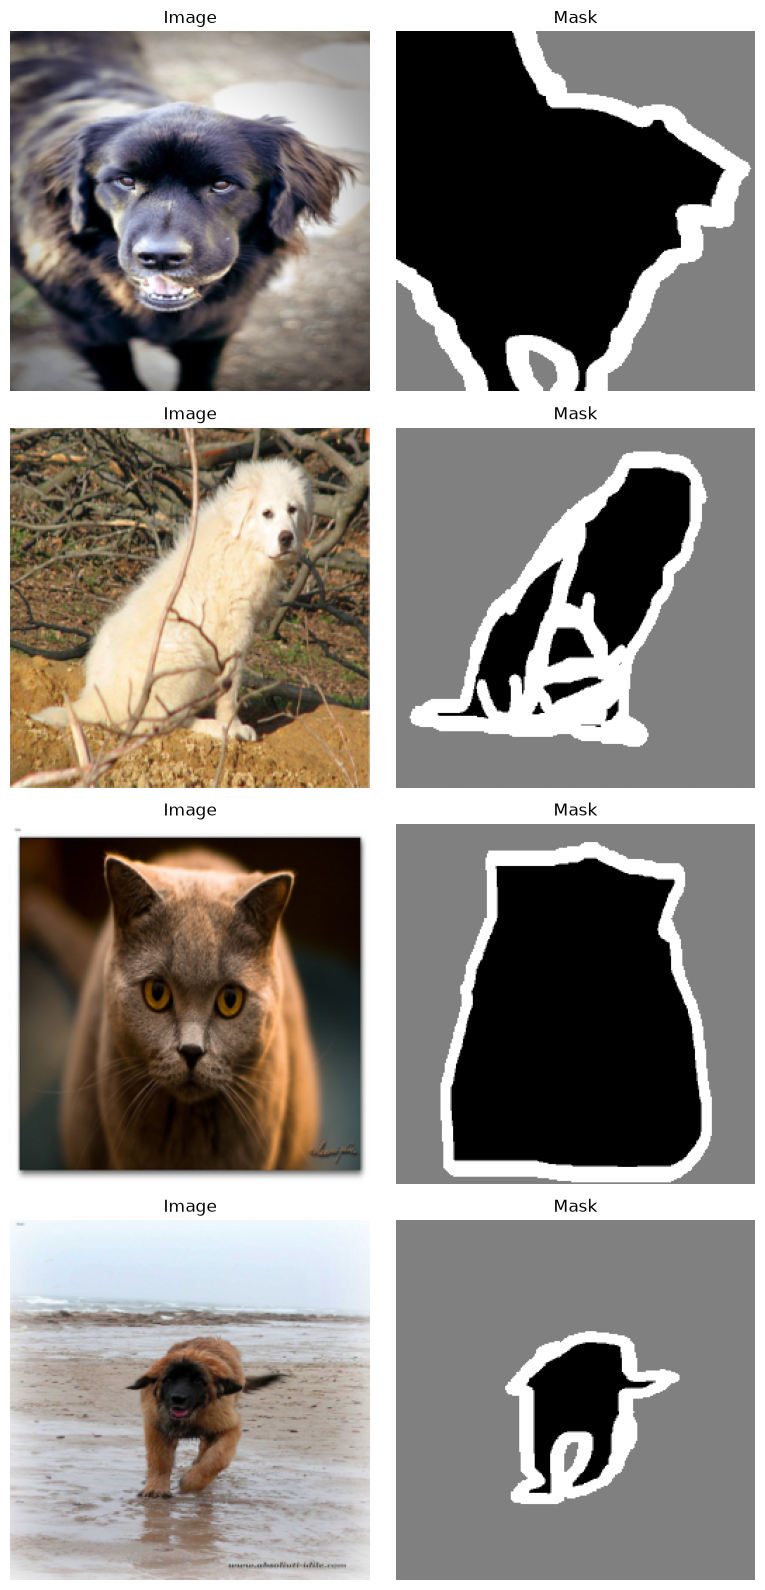

In [3]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_examples(dataloader, num_examples=4):
    """Visualizes a few examples from the dataset."""
    images, masks = next(iter(dataloader))
    fig, axes = plt.subplots(num_examples, 2, figsize=(8, num_examples * 4))

    for i in range(num_examples):
        # Plot image
        img = images[i].permute(1, 2, 0).numpy()
        # Unnormalize if necessary, depends on the transform applied
        # For MNIST normalized to (0.5, ), we'd do:
        # img = img * 0.5 + 0.5
        img = np.clip(img, 0, 1) # Clip to [0, 1] for display
        axes[i, 0].imshow(img)
        axes[i, 0].set_title("Image")
        axes[i, 0].axis('off')

        # Plot mask
        # Squeeze the channel dimension if it exists for single channel masks
        mask = masks[i].squeeze().numpy()
        # Use 'gray' colormap for binary masks or a specific colormap for multi-class
        axes[i, 1].imshow(mask, cmap='gray')
        axes[i, 1].set_title("Mask")
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()

# Visualize examples from the training dataset
visualize_examples(train_loader, num_examples=4)

In [4]:
from torch import optim
from tqdm import tqdm

# Визначення пристрою (GPU, якщо доступно, інакше CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device", device)

# Створюємо екземпляр U-Net моделі
# out_channels=3, оскільки в нас три класи в масці (1, 2, 3)
unet_model = UNet(in_channels=3, out_channels=3)
unet_model.to(device)

# Визначення функції втрат та оптимізатора
# Для багатокласової сегментації використовуємо CrossEntropyLoss
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(unet_model.parameters(), lr=0.001)

# Навчання моделі U-Net
epochs = 1 # Можливо, знадобиться більше епох для кращого результату

for epoch in range(epochs):
    unet_model.train() # Переводимо модель в режим навчання
    running_loss = 0.0
    # Використовуємо tqdm для відображення прогресу
    for images, masks in tqdm(train_loader, desc=f'U-Net Epoch {epoch+1}/{epochs}'):
        # Переміщуємо дані на пристрій
        images, masks = images.to(device), masks.to(device)

        # Оскільки маски мають значення 1, 2, 3, віднімаємо 1, щоб вони стали 0, 1, 2
        # CrossEntropyLoss очікує цільові класи від 0 до C-1
        masks = masks - 1

        # Обнуляємо градієнти оптимізатора
        optimizer.zero_grad()

        # Прямий прохід
        outputs = unet_model(images)
        loss = criterion(outputs, masks)

        # Зворотний прохід та оптимізація
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f'U-Net Epoch {epoch+1}, Loss: {running_loss/len(train_loader)}')

print('Finished Training U-Net')

# Функція для оцінки моделі (можна додати метрики IoU)
def evaluate_unet(model, dataloader, device):
    model.eval() # Переводимо модель в режим оцінки
    total_loss = 0.0
    # Можна додати метрики IoU тут

    with torch.no_grad(): # Вимикаємо розрахунок градієнтів
        for images, masks in tqdm(dataloader, desc='Evaluating U-Net'):
            images, masks = images.to(device), masks.to(device)
            masks = masks - 1 # Приводимо маски до діапазону [0, C-1]

            outputs = model(images)
            loss = criterion(outputs, masks)
            total_loss += loss.item()

            # Тут можна розрахувати IoU або інші метрики
            # predicted_masks = torch.argmax(outputs, dim=1)
            # print(predicted_masks.shape, masks.shape)

    avg_loss = total_loss / len(dataloader)
    print(f'Evaluation Loss: {avg_loss}')
    return avg_loss # Або повертати метрики

# Оцінка моделі на тестовому датасеті (якщо він є)
# На жаль, в OxfordIIITPetDataset немає вбудованого поділу на train/test
# Можна створити його вручну або використати частину train_dataset для оцінки
# evaluate_unet(unet_model, test_loader, device) # Якщо є test_loader

device cuda


U-Net Epoch 1/1: 100%|██████████| 924/924 [34:46<00:00,  2.26s/it]

U-Net Epoch 1, Loss: 0.8170363867889235
Finished Training U-Net


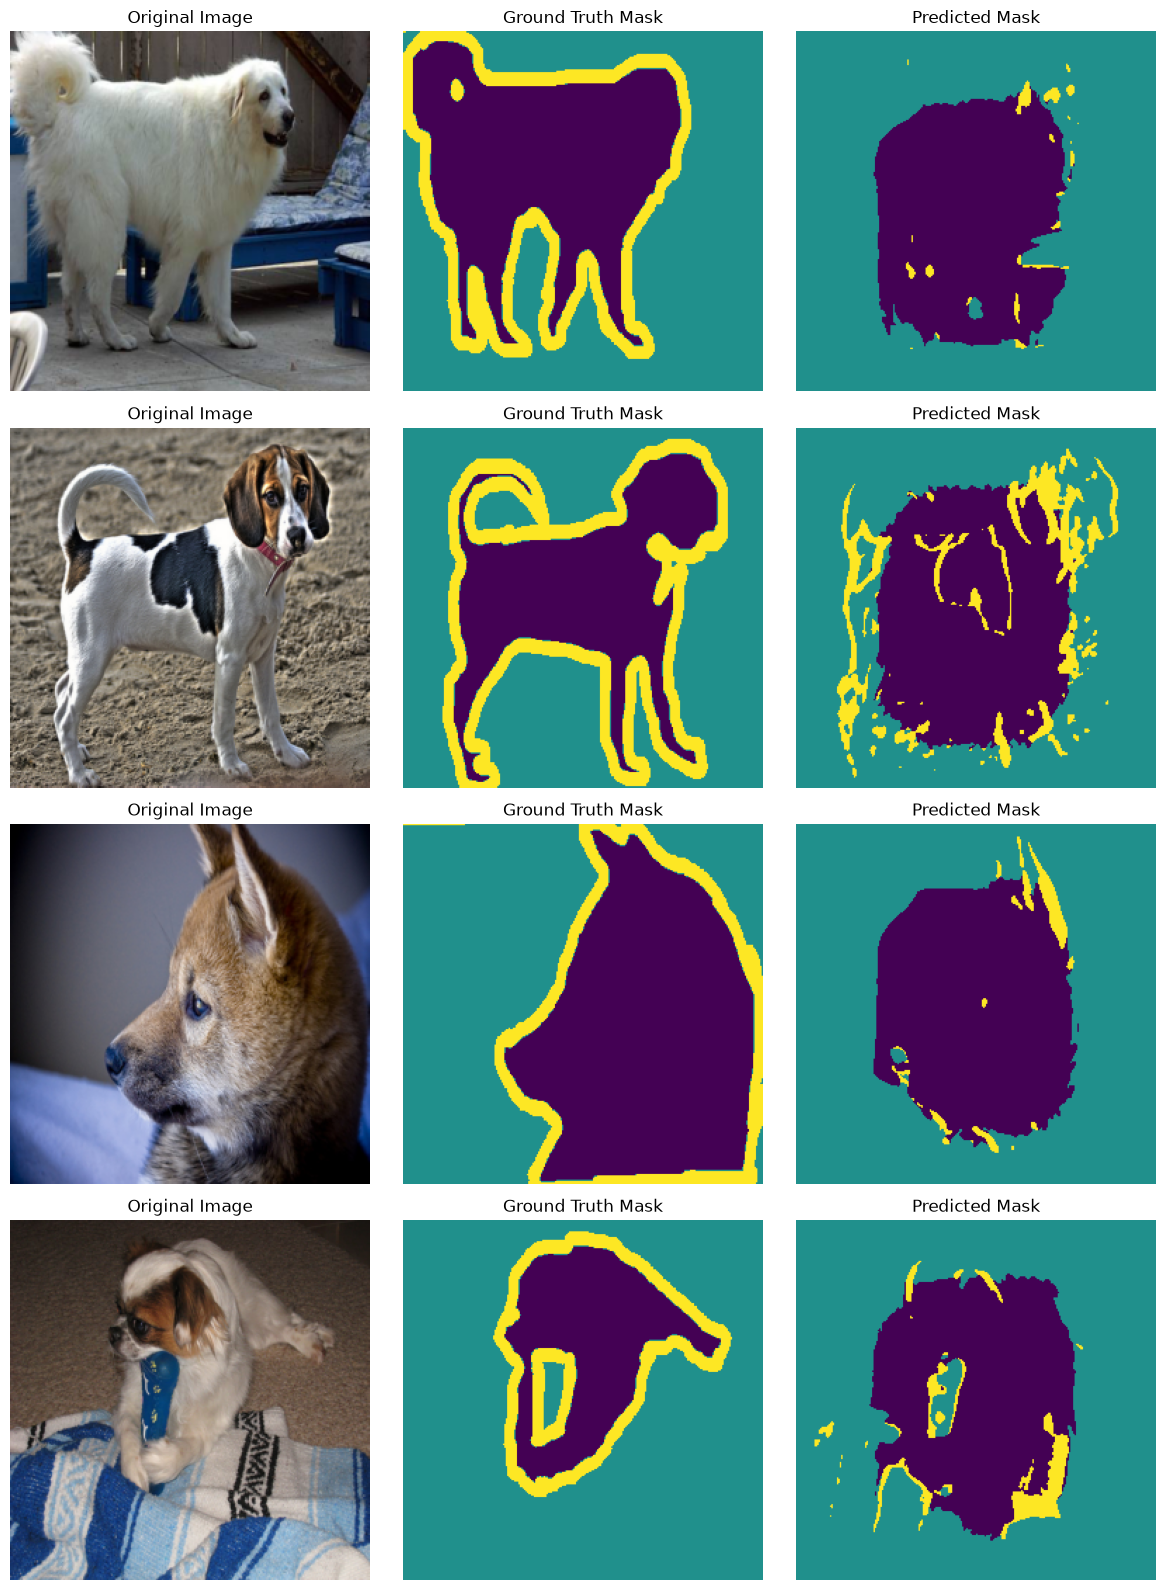

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Функція для візуалізації прогнозу моделі U-Net
def visualize_unet_prediction(model, dataloader, device, num_examples=4):
    model.eval()  # Переводимо модель в режим оцінки
    images, masks = next(iter(dataloader)) # Беремо один батч
    images, masks = images.to(device), masks.to(device)

    with torch.no_grad():
        outputs = model(images)
        predicted_masks = torch.argmax(outputs, dim=1) # Отримуємо передбачені класи для кожного пікселя

    fig, axes = plt.subplots(num_examples, 3, figsize=(12, num_examples * 4))

    # Оскільки ми віднімали 1 від масок для CrossEntropyLoss,
    # додаємо 1 назад для візуалізації, щоб відповідало оригінальним значенням (1, 2, 3)
    masks = masks + 1
    predicted_masks = predicted_masks + 1


    for i in range(num_examples):
        # Plot original image
        img = images[i].permute(1, 2, 0).cpu().numpy()
        img = np.clip(img, 0, 1)
        axes[i, 0].imshow(img)
        axes[i, 0].set_title("Original Image")
        axes[i, 0].axis('off')

        # Plot Ground Truth Mask
        mask = masks[i].squeeze().cpu().numpy()
        axes[i, 1].imshow(mask, cmap='viridis') # Можна використовувати різні colormaps
        axes[i, 1].set_title("Ground Truth Mask")
        axes[i, 1].axis('off')

        # Plot Predicted Mask
        predicted_mask = predicted_masks[i].squeeze().cpu().numpy()
        axes[i, 2].imshow(predicted_mask, cmap='viridis')
        axes[i, 2].set_title("Predicted Mask")
        axes[i, 2].axis('off')

    plt.tight_layout()
    plt.show()

# Візуалізуємо прогнози U-Net на кількох прикладах
visualize_unet_prediction(unet_model, train_loader, device, num_examples=4)
